# Proyek Analisis Data: [Bike Sharing Dataset]
- **Nama:** Elisia Nurin Afifatur Rahmah
- **Email:** elisianurin6319@gmail.com
- **ID Dicoding:** elisia_nurin_6319

## Menentukan Pertanyaan Bisnis

### Pertanyaan Bisnis (SMART Questions)

Berdasarkan karakteristik Bike Sharing Dataset yang mencakup data penyewaan sepeda di Washington D.C. selama tahun 2011–2012, penelitian ini berfokus pada pola permintaan penyewaan sepeda berdasarkan waktu, hari kerja, kondisi cuaca, dan karakteristik pengguna.

**Pertanyaan 1:**

Bagaimana perkembangan jumlah penyewaan sepeda harian dari Januari 2011 hingga Desember 2012, dan bulan apa yang memiliki rata-rata penyewaan harian tertinggi selama periode tersebut?

**Pertanyaan 2:**

Pada jam berapa jumlah penyewaan sepeda mencapai puncaknya, dan bagaimana perbedaan pola penyewaan per jam antara hari kerja dan hari non-kerja (akhir pekan dan hari libur) selama tahun 2011–2012?

**Pertanyaan 3:**

Bagaimana perbedaan rata-rata jumlah penyewaan sepeda berdasarkan empat kategori kondisi cuaca selama periode 2011–2012?

**Pertanyaan 4:**

Bagaimana perbandingan rata-rata jumlah penyewaan sepeda oleh pengguna casual dan registered pada masing-masing musim selama tahun 2011–2012?

### Tujuan Analisis

1. Mengidentifikasi tren permintaan penyewaan sepeda berdasarkan bulan dan tahun.
2. Mengidentifikasi jam sibuk serta perbedaan pola penyewaan antara hari kerja dan hari non-kerja.
3. Mengevaluasi perbedaan rata-rata volume penyewaan berdasarkan kategori cuaca.
4. Membandingkan rata-rata penyewaan pengguna casual dan registered berdasarkan musim sebagai dasar rekomendasi strategi operasional dan pemasaran.

## Import Semua Packages/Library yang Digunakan

In [31]:
# Import library untuk analisis data
import pandas as pd
import numpy as np

# Import library untuk visualisasi data
import matplotlib.pyplot as plt
import seaborn as sns

# Import library pendukung
import os
import warnings
from pathlib import Path

# Mengatur tampilan visualisasi
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["axes.titlesize"] = 14
plt.rcParams["axes.labelsize"] = 11

# Menghilangkan peringatan yang tidak diperlukan
warnings.filterwarnings("ignore")

print("Semua library berhasil diimpor!")


Semua library berhasil diimpor!


## Data Wrangling

### Gathering Data

### Load Dataset Bike Sharing

Pada tahap ini dilakukan proses pengumpulan data (*data gathering*) dengan memuat dataset Bike Sharing yang diperoleh dari sumber dataset publik. Dataset ini merepresentasikan aktivitas penyewaan sepeda di Washington D.C. selama periode tahun 2011–2012.

Dataset yang digunakan terdiri atas dua berkas utama:

1. hour.csv 
2. day.csv

Kedua dataset dimuat menggunakan library Pandas melalui fungsi `read_csv()`. Dataset `hour.csv` digunakan untuk menganalisis pola penyewaan berdasarkan jam, sedangkan `day.csv` digunakan untuk menganalisis tren penyewaan harian, bulanan, dan musiman.

Setelah proses pemuatan data, dilakukan pemeriksaan ukuran dataset dan penampilan lima baris pertama untuk memahami struktur awal data sebelum memasuki tahap *Assessing Data*.

In [ ]:
# Menentukan lokasi folder dataset
DATA_DIR = Path("../data/raw")

# Membaca dataset Bike Sharing
hour_df = pd.read_csv(DATA_DIR / "hour.csv")
day_df = pd.read_csv(DATA_DIR / "day.csv")

# Menampilkan ukuran dataset
print("Ukuran dataset per jam:", hour_df.shape)
print("Ukuran dataset per hari:", day_df.shape)

# Menampilkan 5 data pertama
print("\nDataset per jam:")
display(hour_df.head())

print("\nDataset per hari:")
display(day_df.head())

Ukuran dataset per jam: (17379, 17)
Ukuran dataset per hari: (731, 16)

Dataset per jam:


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1



Dataset per hari:


,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


**Insight:**
- Dataset `hour.csv` terdiri dari 17.379 baris dan 17 kolom yang merepresentasikan data penyewaan sepeda setiap jam.
- Dataset `day.csv` terdiri dari 731 baris dan 16 kolom yang merepresentasikan data penyewaan sepeda setiap hari.

### Assessing Data

#### Identifying Data Quality Issues

Pada tahap ini dilakukan pemeriksaan kualitas data untuk mengidentifikasi potensi permasalahan pada dataset, meliputi:
- Missing values atau nilai yang kosong.
- Duplicate data atau data duplikat.
- Ketidaksesuaian tipe data.
- Nilai statistik yang tidak wajar atau berpotensi menjadi outlier.

In [ ]:
# 1. Memeriksa informasi dataset
print("INFORMASI DATASET PER JAM")
hour_df.info()

print("\nINFORMASI DATASET PER HARI")
day_df.info()


# 2. Memeriksa missing values
print("\nMISSING VALUES DATASET PER JAM")
print(hour_df.isnull().sum())

print("\nMISSING VALUES DATASET PER HARI")
print(day_df.isnull().sum())


# 3. Memeriksa data duplikat
print("\nJUMLAH DATA DUPLIKAT")
print("Dataset per jam:", hour_df.duplicated().sum())
print("Dataset per hari:", day_df.duplicated().sum())


# 4. Memeriksa statistik deskriptif
print("\nSTATISTIK DATASET PER JAM")
display(hour_df.describe())

print("\nSTATISTIK DATASET PER HARI")
display(day_df.describe())

KeyboardInterrupt: 

**Steps to Take:**
- Mengubah tipe data kolom `dteday` pada dataset `hour_df` dan `day_df` menjadi tipe datetime agar dapat digunakan dalam analisis berbasis waktu.
- Menghapus data duplikat apabila ditemukan pada dataset.
- Mengubah kolom kategorikal seperti `season`, `yr`, `mnth`, `holiday`, `weekday`, `workingday`, dan `weathersit` menjadi tipe category agar pengolahan data lebih sesuai dengan karakteristik variabel.

**Insight:**
- Kolom `dteday` pada kedua dataset telah dikonversi menjadi tipe data datetime sehingga dapat digunakan untuk analisis berdasarkan tanggal, bulan, dan tahun.
- Kolom kategorikal telah diubah menjadi tipe category untuk mempermudah pengelompokan dan analisis data.
- Data duplikat telah ditangani menggunakan `drop_duplicates()`. Dataset siap digunakan untuk tahap Exploratory Data Analysis (EDA).

### Cleaning Data

### Data Cleaning and Transformation

Tahap *cleaning data* dilakukan untuk mempersiapkan dataset agar memiliki format dan struktur yang sesuai untuk proses analisis lebih lanjut.

Pada tahap ini, direncanakan beberapa proses pembersihan dan transformasi data, yaitu:

1. **Konversi tipe data tanggal:** Mengubah kolom `dteday` pada dataset `hour_df` dan `day_df` menjadi tipe `datetime`.
2. **Penanganan data duplikat:** Mengidentifikasi dan menghapus baris data yang terduplikasi menggunakan fungsi `drop_duplicates()`.
3. **Transformasi variabel kategorikal:** Mengubah kolom `season`, `yr`, `mnth`, `holiday`, `weekday`, `workingday`, dan `weathersit` menjadi tipe data `category`.
4. **Pemeriksaan hasil pembersihan:** Memeriksa kembali tipe data, ukuran dataset, dan jumlah *missing values* setelah proses cleaning dilakukan.

In [ ]:
# Mengubah kolom tanggal menjadi tipe datetime
hour_df["dteday"] = pd.to_datetime(hour_df["dteday"])
day_df["dteday"] = pd.to_datetime(day_df["dteday"])

# Menghapus data duplikat jika ditemukan
hour_df.drop_duplicates(inplace=True)
day_df.drop_duplicates(inplace=True)

# Mengubah kolom kategorikal menjadi tipe category
categorical_columns = [
    "season", "yr", "mnth", "holiday",
    "weekday", "workingday", "weathersit"
]

for col in categorical_columns:
    hour_df[col] = hour_df[col].astype("category")
    day_df[col] = day_df[col].astype("category")

# Memeriksa hasil pembersihan
print("Tipe data tanggal setelah diperbaiki:")
print("hour_df:", hour_df["dteday"].dtype)
print("day_df:", day_df["dteday"].dtype)

print("\nUkuran dataset setelah cleaning:")
print("hour_df:", hour_df.shape)
print("day_df:", day_df.shape)

print("\nMissing values setelah cleaning:")
print("hour_df:", hour_df.isnull().sum().sum())
print("day_df:", day_df.isnull().sum().sum())

# Membuat folder cleaned
CLEANED_DIR = Path("../data/cleaned")
CLEANED_DIR.mkdir(parents=True, exist_ok=True)

# Menyimpan dataset hasil cleaning
hour_df.to_csv(CLEANED_DIR / "hour_cleaned.csv", index=False)
day_df.to_csv(CLEANED_DIR / "day_cleaned.csv", index=False)

print("Dataset hasil cleaning berhasil disimpan!")

Tipe data tanggal setelah diperbaiki:
hour_df: datetime64[ns]
day_df: datetime64[ns]

Ukuran dataset setelah cleaning:
hour_df: (17379, 17)
day_df: (731, 16)

Missing values setelah cleaning:
hour_df: 0
day_df: 0
Dataset hasil cleaning berhasil disimpan!


**Insight:**
- Dataset `hour_df` memiliki 17.379 baris dan 17 kolom, sedangkan `day_df` memiliki 731 baris dan 16 kolom.
- Kedua dataset tidak memiliki missing values, sehingga tidak diperlukan penanganan data kosong.
- Struktur dataset memiliki dua jenis periode pengamatan, yaitu per jam dan per hari, yang dapat digunakan untuk analisis pola penyewaan sepeda.

## Exploratory Data Analysis (EDA)

### Eksplorasi Pola Penyewaan Sepeda

In [ ]:
# 1. Statistik deskriptif jumlah penyewaan
print("STATISTIK PENYEWAAN SEPEDA")
display(day_df[["casual", "registered", "cnt"]].describe())


# 2. Rata-rata penyewaan berdasarkan bulan
monthly_rentals = (
    day_df.groupby("mnth", observed=True)["cnt"]
    .mean()
    .reset_index()
)

monthly_rentals.columns = ["Bulan", "Rata-rata Penyewaan"]
display(monthly_rentals)


# 3. Rata-rata penyewaan berdasarkan jam
hourly_rentals = (
    hour_df.groupby("hr", observed=True)["cnt"]
    .mean()
    .reset_index()
)

hourly_rentals.columns = ["Jam", "Rata-rata Penyewaan"]
display(hourly_rentals)


# 4. Rata-rata penyewaan berdasarkan hari kerja
workingday_rentals = (
    hour_df.groupby("workingday", observed=True)["cnt"]
    .mean()
    .reset_index()
)

workingday_rentals.columns = ["Hari Kerja", "Rata-rata Penyewaan"]
display(workingday_rentals)


# 5. Rata-rata penyewaan berdasarkan kondisi cuaca
weather_rentals = (
    day_df.groupby("weathersit", observed=True)["cnt"]
    .mean()
    .reset_index()
)

weather_rentals.columns = ["Kondisi Cuaca", "Rata-rata Penyewaan"]
display(weather_rentals)

STATISTIK PENYEWAAN SEPEDA


,casual,registered,cnt
count,731.000000,731.000000,731.000000
mean,848.176471,3656.172367,4504.348837
std,686.622488,1560.256377,1937.211452
min,2.000000,20.000000,22.000000
25%,315.500000,2497.000000,3152.000000
50%,713.000000,3662.000000,4548.000000
75%,1096.000000,4776.500000,5956.000000
max,3410.000000,6946.000000,8714.000000


,Bulan,Rata-rata Penyewaan
0,1,2176.338710
1,2,2655.298246
2,3,3692.258065
3,4,4484.900000
4,5,5349.774194
5,6,5772.366667
6,7,5563.677419
7,8,5664.419355
8,9,5766.516667
9,10,5199.225806


,Jam,Rata-rata Penyewaan
0,0,53.898072
1,1,33.375691
2,2,22.869930
3,3,11.727403
4,4,6.352941
5,5,19.889819
6,6,76.044138
7,7,212.064649
8,8,359.011004
9,9,219.309491


,Hari Kerja,Rata-rata Penyewaan
0,0,181.405332
1,1,193.207754


,Kondisi Cuaca,Rata-rata Penyewaan
0,1,4876.786177
1,2,4035.862348
2,3,1803.285714


**Insight:**
- Dataset Bike Sharing menyediakan informasi penyewaan sepeda berdasarkan waktu, karakteristik pengguna, dan kondisi lingkungan.
- Eksplorasi awal dilakukan untuk mengidentifikasi pola penyewaan berdasarkan bulan, jam, hari kerja, dan kondisi cuaca sebagai dasar analisis visualisasi.

## Visualization & Explanatory Analysis

### Pertanyaan 1:

Bagaimana perkembangan jumlah penyewaan sepeda berdasarkan bulan selama tahun 2011–2012, dan bulan apa yang memiliki rata-rata penyewaan tertinggi?

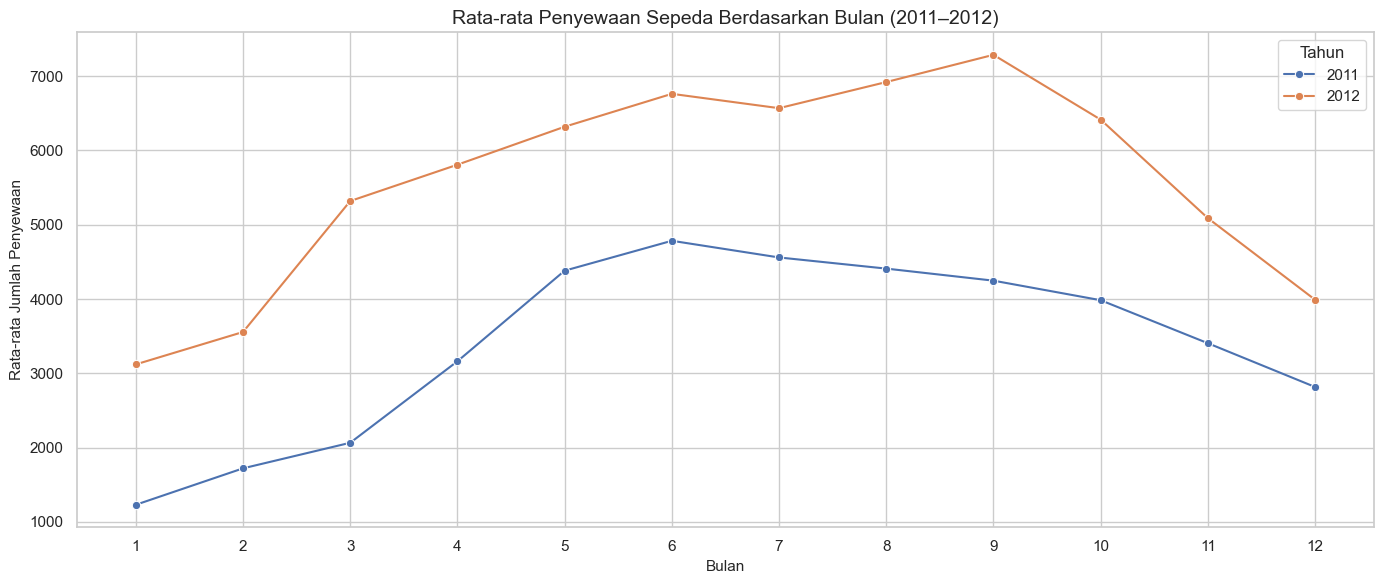

Bulan dengan rata-rata penyewaan tertinggi: 6


In [ ]:
# Menghitung total penyewaan setiap bulan
monthly_trend = (
    day_df.groupby(["yr", "mnth"], observed=True)["cnt"]
    .mean()
    .reset_index()
)

monthly_trend["Tahun"] = monthly_trend["yr"].map({
    0: "2011",
    1: "2012"
})

monthly_trend["Bulan"] = monthly_trend["mnth"].astype(int)

# Membuat grafik tren penyewaan
plt.figure(figsize=(14, 6))

sns.lineplot(
    data=monthly_trend,
    x="Bulan",
    y="cnt",
    hue="Tahun",
    marker="o"
)

plt.title("Rata-rata Penyewaan Sepeda Berdasarkan Bulan (2011–2012)")
plt.xlabel("Bulan")
plt.ylabel("Rata-rata Jumlah Penyewaan")
plt.xticks(range(1, 13))
plt.legend(title="Tahun")
plt.tight_layout()
plt.show()

# Menentukan bulan dengan rata-rata penyewaan tertinggi
highest_month = (
    day_df.groupby("mnth", observed=True)["cnt"]
    .mean()
    .idxmax()
)

print("Bulan dengan rata-rata penyewaan tertinggi:", highest_month)

### Pertanyaan 2:

Pada jam berapa penyewaan sepeda mencapai puncaknya, dan bagaimana perbedaan pola penyewaan antara hari kerja dan hari non-kerja?

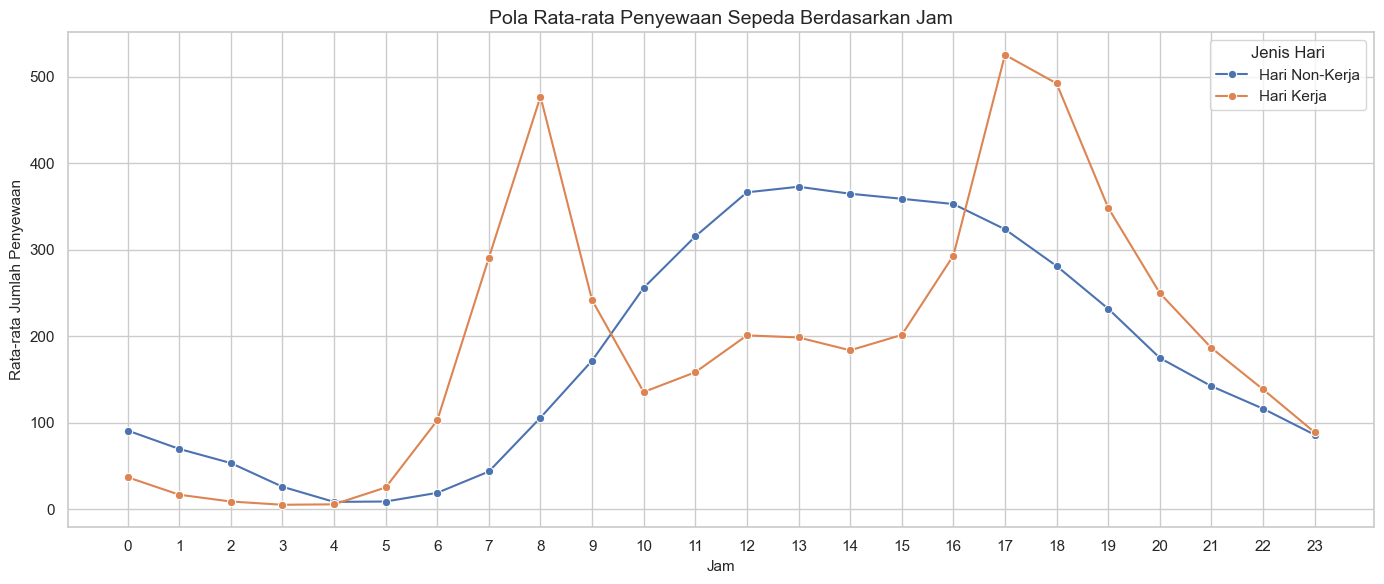

Jam dengan rata-rata penyewaan tertinggi: 17


In [ ]:
# Menghitung rata-rata penyewaan berdasarkan jam dan hari kerja
hourly_pattern = (
    hour_df.groupby(["hr", "workingday"], observed=True)["cnt"]
    .mean()
    .reset_index()
)

hourly_pattern["Jenis Hari"] = hourly_pattern["workingday"].map({
    0: "Hari Non-Kerja",
    1: "Hari Kerja"
})

# Membuat grafik pola penyewaan per jam
plt.figure(figsize=(14, 6))

sns.lineplot(
    data=hourly_pattern,
    x="hr",
    y="cnt",
    hue="Jenis Hari",
    marker="o"
)

plt.title("Pola Rata-rata Penyewaan Sepeda Berdasarkan Jam")
plt.xlabel("Jam")
plt.ylabel("Rata-rata Jumlah Penyewaan")
plt.xticks(range(0, 24))
plt.legend(title="Jenis Hari")
plt.tight_layout()
plt.show()

# Menentukan jam dengan rata-rata penyewaan tertinggi
peak_hour = (
    hour_df.groupby("hr", observed=True)["cnt"]
    .mean()
    .idxmax()
)

print("Jam dengan rata-rata penyewaan tertinggi:", peak_hour)

**Insight:**
- Pada hari kerja, penyewaan sepeda menunjukkan dua waktu puncak, yaitu sekitar pukul 08.00 dan pukul 17.00–18.00. Pola ini mengindikasikan bahwa sepeda banyak digunakan untuk mendukung aktivitas perjalanan pada jam berangkat dan pulang kerja.
- Pada hari non-kerja, penyewaan cenderung meningkat secara bertahap pada pagi hari dan mencapai tingkat tertinggi sekitar pukul 12.00–14.00. Hal ini menunjukkan pola penggunaan yang berbeda dibandingkan hari kerja.

### Pertanyaan 3:

Bagaimana perbedaan rata-rata jumlah penyewaan sepeda per jam berdasarkan kategori kondisi cuaca selama periode 2011–2012, serta bagaimana keterbatasan jumlah observasi pada kategori cuaca ekstrem memengaruhi interpretasi hasil?

,weathersit,mean,count,Kondisi Cuaca
0,1,204.869272,11413,Cerah / Berawan
1,2,175.165493,4544,Berkabut / Berawan
2,3,111.579281,1419,Hujan / Salju Ringan
3,4,74.333333,3,Cuaca Ekstrem


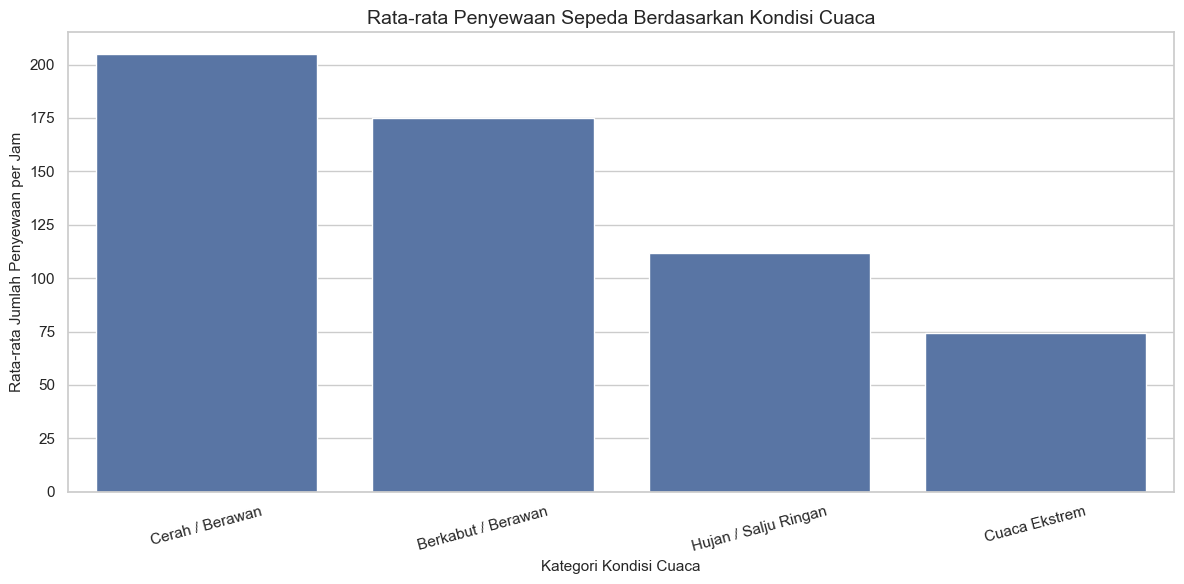

In [ ]:
# Menghitung jumlah observasi dan rata-rata penyewaan
# berdasarkan kategori kondisi cuaca
weather_rentals = (
    hour_df.groupby("weathersit", observed=True)["cnt"]
    .agg(
        jumlah_observasi="count",
        rata_rata_penyewaan="mean"
    )
    .reset_index()
)

weather_labels = {
    1: "Cerah / Berawan",
    2: "Berkabut / Berawan",
    3: "Hujan / Salju Ringan",
    4: "Cuaca Ekstrem"
}

weather_rentals["Kondisi Cuaca"] = (
    weather_rentals["weathersit"].map(weather_labels)
)

display(weather_rentals)

# Visualisasi kategori cuaca 1–3
# Kategori 4 tetap ditampilkan dalam tabel, tetapi tidak
# dimasukkan ke grafik perbandingan utama karena observasinya sangat sedikit.
weather_comparison = weather_rentals[
    weather_rentals["weathersit"].isin([1, 2, 3])
]

plt.figure(figsize=(10, 6))

sns.barplot(
    data=weather_comparison,
    x="Kondisi Cuaca",
    y="rata_rata_penyewaan"
)

plt.title("Rata-rata Penyewaan Sepeda Berdasarkan Kondisi Cuaca")
plt.xlabel("Kategori Kondisi Cuaca")
plt.ylabel("Rata-rata Penyewaan Sepeda per Jam")
plt.tight_layout()
plt.show()

**Insight:**

- Kondisi cuaca kategori 1 (cerah atau berawan sebagian) memiliki rata-rata penyewaan tertinggi, yaitu sekitar 204,87 sepeda per jam.
- Pada kategori 2 (berkabut dan berawan), rata-rata penyewaan mencapai sekitar 175,17 sepeda per jam.
- Pada kategori 3 (hujan atau salju ringan), rata-rata penyewaan menurun menjadi sekitar 111,58 sepeda per jam.
- Kategori 4 (cuaca ekstrem) memiliki rata-rata penyewaan sekitar 74,33 sepeda per jam. Namun, kategori ini hanya memiliki tiga observasi sehingga hasilnya tidak dapat dianggap mewakili pola penyewaan pada kondisi cuaca ekstrem secara umum.

**Catatan keterbatasan data:**

Analisis menggunakan `hour.csv` karena menyediakan data penyewaan dalam interval per jam dan mencakup empat kategori cuaca. Meskipun demikian, ketimpangan jumlah observasi antar kategori, khususnya kategori 4, membatasi kekuatan interpretasi perbandingan. Oleh karena itu, kesimpulan utama difokuskan pada kategori cuaca 1–3, sedangkan kategori 4 hanya disajikan sebagai informasi tambahan.

### Pertanyaan 4:

Bagaimana perbandingan rata-rata jumlah penyewaan sepeda oleh pengguna casual dan registered pada masing-masing musim selama tahun 2011–2012?

,season,casual,registered,cnt,Musim
0,1,334.928177,2269.204420,2604.132597,Spring
1,2,1106.097826,3886.233696,4992.331522,Summer
2,3,1202.611702,4441.691489,5644.303191,Fall
3,4,729.112360,3999.050562,4728.162921,Winter


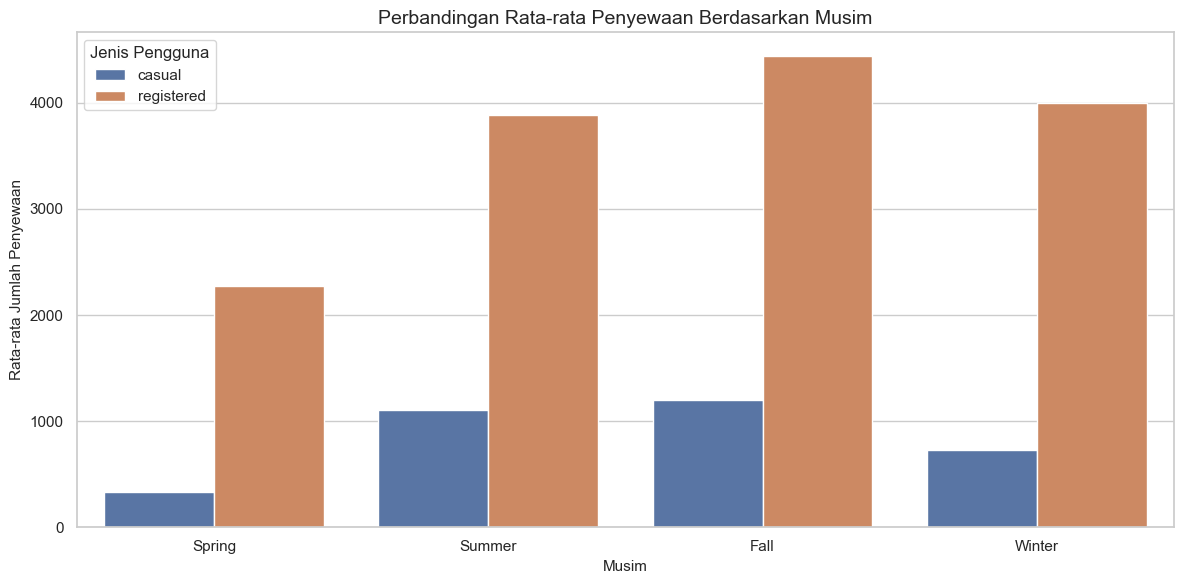

In [ ]:
# Menghitung rata-rata penyewaan berdasarkan musim
seasonal_rentals = (
    day_df.groupby("season", observed=True)[["casual", "registered", "cnt"]]
    .mean()
    .reset_index()
)

seasonal_rentals["Musim"] = seasonal_rentals["season"].map({
    1: "Spring",
    2: "Summer",
    3: "Fall",
    4: "Winter"
})

display(seasonal_rentals)

# Visualisasi perbandingan pengguna berdasarkan musim
seasonal_plot = seasonal_rentals.melt(
    id_vars="Musim",
    value_vars=["casual", "registered"],
    var_name="Jenis Pengguna",
    value_name="Rata-rata Penyewaan"
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=seasonal_plot,
    x="Musim",
    y="Rata-rata Penyewaan",
    hue="Jenis Pengguna"
)

plt.title("Perbandingan Rata-rata Penyewaan Berdasarkan Musim")
plt.xlabel("Musim")
plt.ylabel("Rata-rata Jumlah Penyewaan")
plt.tight_layout()
plt.show()

**Insight:**
- Musim gugur (Fall) memiliki rata-rata penyewaan tertinggi, baik pada pengguna casual maupun registered.
- Rata-rata penyewaan pengguna casual pada musim gugur mencapai sekitar 1.202,61 sepeda per hari, sedangkan pengguna registered mencapai sekitar 4.441,69 sepeda per hari.
- Musim semi (Spring) memiliki rata-rata penyewaan terendah pada kedua kelompok pengguna.
- Pengguna registered mendominasi penyewaan pada seluruh musim dibandingkan pengguna casual.

## Conclusion & Recommendation

### Conclusion

- **Conclusion Pertanyaan 1:** Berdasarkan data penyewaan sepeda selama tahun 2011–2012, rata-rata jumlah penyewaan harian menunjukkan variasi pada setiap bulan. Bulan Juni memiliki rata-rata penyewaan harian tertinggi, yaitu sekitar 5.772 sepeda per hari, sedangkan Januari memiliki rata-rata terendah, yaitu sekitar 2.176 sepeda per hari. Hasil ini menunjukkan bahwa permintaan penyewaan sepeda cenderung lebih tinggi pada pertengahan tahun dibandingkan awal tahun.

- **Conclusion Pertanyaan 2:** Penyewaan sepeda mencapai rata-rata tertinggi pada pukul 17.00. Pola penyewaan berbeda antara hari kerja dan hari non-kerja. Pada hari kerja, terdapat dua waktu puncak penyewaan, yaitu sekitar pukul 08.00 dan pukul 17.00–18.00. Sementara itu, pada hari non-kerja, penyewaan cenderung meningkat menjelang siang dan mencapai puncak sekitar pukul 13.00. Perbedaan ini menunjukkan bahwa sepeda pada hari kerja lebih banyak digunakan untuk menunjang mobilitas rutin, sedangkan pada hari non-kerja penggunaannya cenderung meningkat pada siang hari.

- **Conclusion Pertanyaan 3:** Kondisi cuaca berhubungan dengan perbedaan rata-rata jumlah penyewaan sepeda. Berdasarkan data per jam, kondisi cuaca kategori 1 (cerah, sedikit awan, atau berawan sebagian) memiliki rata-rata penyewaan tertinggi, yaitu sekitar 204,87 sepeda per jam. Pada kategori 2 (berkabut dan berawan), rata-ratanya sekitar 175,17 sepeda per jam, sedangkan kategori 3 (hujan ringan atau salju ringan) sekitar 111,58 sepeda per jam. Kategori 4 (hujan lebat atau kondisi cuaca ekstrem) memiliki rata-rata sekitar 74,33 sepeda per jam. Namun, kategori 4 hanya memiliki tiga observasi sehingga hasilnya perlu ditafsirkan secara hati-hati. Secara umum, kondisi cuaca yang lebih baik cenderung diikuti oleh jumlah penyewaan sepeda yang lebih tinggi.

- **Conclusion Pertanyaan 4:** Perbandingan berdasarkan musim menunjukkan bahwa musim gugur (Fall) memiliki rata-rata penyewaan tertinggi, baik pada pengguna casual maupun registered. Rata-rata penyewaan pengguna casual pada musim gugur mencapai sekitar 1.202,61 sepeda per hari, sedangkan pengguna registered mencapai sekitar 4.441,69 sepeda per hari. Sebaliknya, musim semi (Spring) memiliki rata-rata penyewaan terendah untuk kedua kelompok pengguna. Selain itu, pengguna registered secara konsisten memiliki rata-rata penyewaan lebih tinggi dibandingkan pengguna casual pada seluruh musim. Hal ini menunjukkan bahwa pengguna terdaftar merupakan kontributor utama dalam aktivitas penyewaan sepeda.

### Rekomendasi Action Item

- **Optimalisasi ketersediaan armada:** Pengelola perlu meningkatkan kesiapan armada pada jam sibuk, khususnya pukul 07.00–09.00 dan 16.00–18.00 pada hari kerja. Penyesuaian jumlah armada juga dapat dilakukan berdasarkan pola permintaan bulanan dan musiman, terutama ketika memasuki bulan Juni dan musim gugur.

- **Strategi berdasarkan kondisi cuaca:** Pengelola dapat menyesuaikan strategi operasional berdasarkan kondisi cuaca. Pada kondisi cerah, ketersediaan sepeda dapat dioptimalkan untuk mengantisipasi peningkatan permintaan. Sementara itu, pada kondisi cuaca buruk, perhatian perlu diberikan pada keselamatan pengguna dan pemantauan kondisi operasional.

- **Strategi peningkatan pengguna casual:** Mengembangkan program promosi, diskon keanggotaan, dan paket berlangganan untuk mendorong pengguna casual menjadi pengguna registered, dengan mempertimbangkan pola permintaan pada setiap musim.